In [40]:
import os
os.environ['PYTHONPATH'] = '/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master'

In [41]:
import numpy as np, matplotlib.pyplot as plt, numba, os, random, scipy, subprocess
import scipy.stats as st, sys, seaborn as sns, pandas as pd, matplotlib.pyplot as plt, sys
from sklearn.metrics import confusion_matrix
from joblib import Parallel, delayed

In [42]:
import sys
sys.path.insert(0, '/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master')  # the folder CONTAINING bench/

import bench
print(bench.__file__)  # should point into your bench-master folder, not site-packages

from bench.diffusion_models import sample_signal, sm_free_r_soma

/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master/bench/__init__.py


In [43]:
bvecs = "/Users/ecd25/Desktop/BENCH/one_versus_many/protocols/pre_1200_bvecs"
bvals = "/Users/ecd25/Desktop/BENCH/one_versus_many/protocols/pre_1200_bvals"
standard_model_dt = "/Users/ecd25/Desktop/BENCH/Soma_Model/trained_models/ss_preop_standard_model_free_soma_dt"

In [44]:
!bench diff-train --model sm_free_r_soma --bvals $bvals --summarytype dt --output $standard_model_dt

Parameters of sm_free_r_soma are:['s_iso', 's_in', 's_ex', 's_soma', 'odi', 'd_iso', 'd_in', 'd_ex', 'tau', 'r_soma']
The model is trained on the following summary measurements: ['b0.0_mean', 'b1.2_md', 'b1.2_fa']
Generating 10000 training samples...
Training models of change for ['s_iso', 's_in', 's_ex', 's_soma', 'odi', 'd_iso', 'd_in', 'd_ex', 'tau', 'r_soma']. /rThis may take up to a few hours depending on the number of samples and the number of change vectors.
Processing Jobs: 100%|███████████████████████| 10/10 [00:00<00:00, 11379.01it/s]
optimized regression weights for s_soma mean
optimized regression weights for s_iso mean
optimized regression weights for s_in mean
optimized regression weights for d_in mean
optimized regression weights for s_ex mean
optimized regression weights for r_soma mean
optimized regression weights for odi mean
optimized regression weights for d_iso mean
optimized regression weights for tau mean
optimized regression weights for d_ex mean
optimized regre

In [45]:
from bench import diffusion_models, model_inversion, change_model, acquisition, plot

In [49]:
forward_model = diffusion_models.sm_free_r_soma
shm_deg = 2

acq = acquisition.Acquisition.from_bval_bvec(bvals, bvecs, b0_threshold=0.5)
func_bench, measurement_names = change_model.summary_decorator(
    forward_model, bvals=acq.bvals, bvecs=acq.bvecs, summary_type='sh', sh_degree=2)
priors_bench = diffusion_models.prior_distributions[forward_model.__name__]

In [50]:
tr = change_model.Trainer(
    forward_model=func_bench, 
    kwargs={'noise_std':0},
    priors=priors_bench, 
    measurement_names=measurement_names)

mdl = tr.train(n_samples=200, verbose=1)

The provided function does not work with the given parameters and args.


TypeError: dot() got an unexpected keyword argument 'r'

In [51]:
n_test_samples = 100
noise_level = 0.02
effect_size = 0.3

true_change, data, data2, sn = tr.generate_test_samples(
        n_samples=n_test_samples, noise_std=noise_level, n_repeats=50, effect_size=effect_size, parallel=True)
    
probs, infered_change_bench, amount, _ = mdl.infer(data, data2 - data, sn)

Generating 100 test samples:


TypeError: sm_w_soma() got an unexpected keyword argument 'd_soma'

<Axes: title={'center': 'BENCH: SM w free r Soma'}, xlabel='Actual change', ylabel='Inferred Change'>

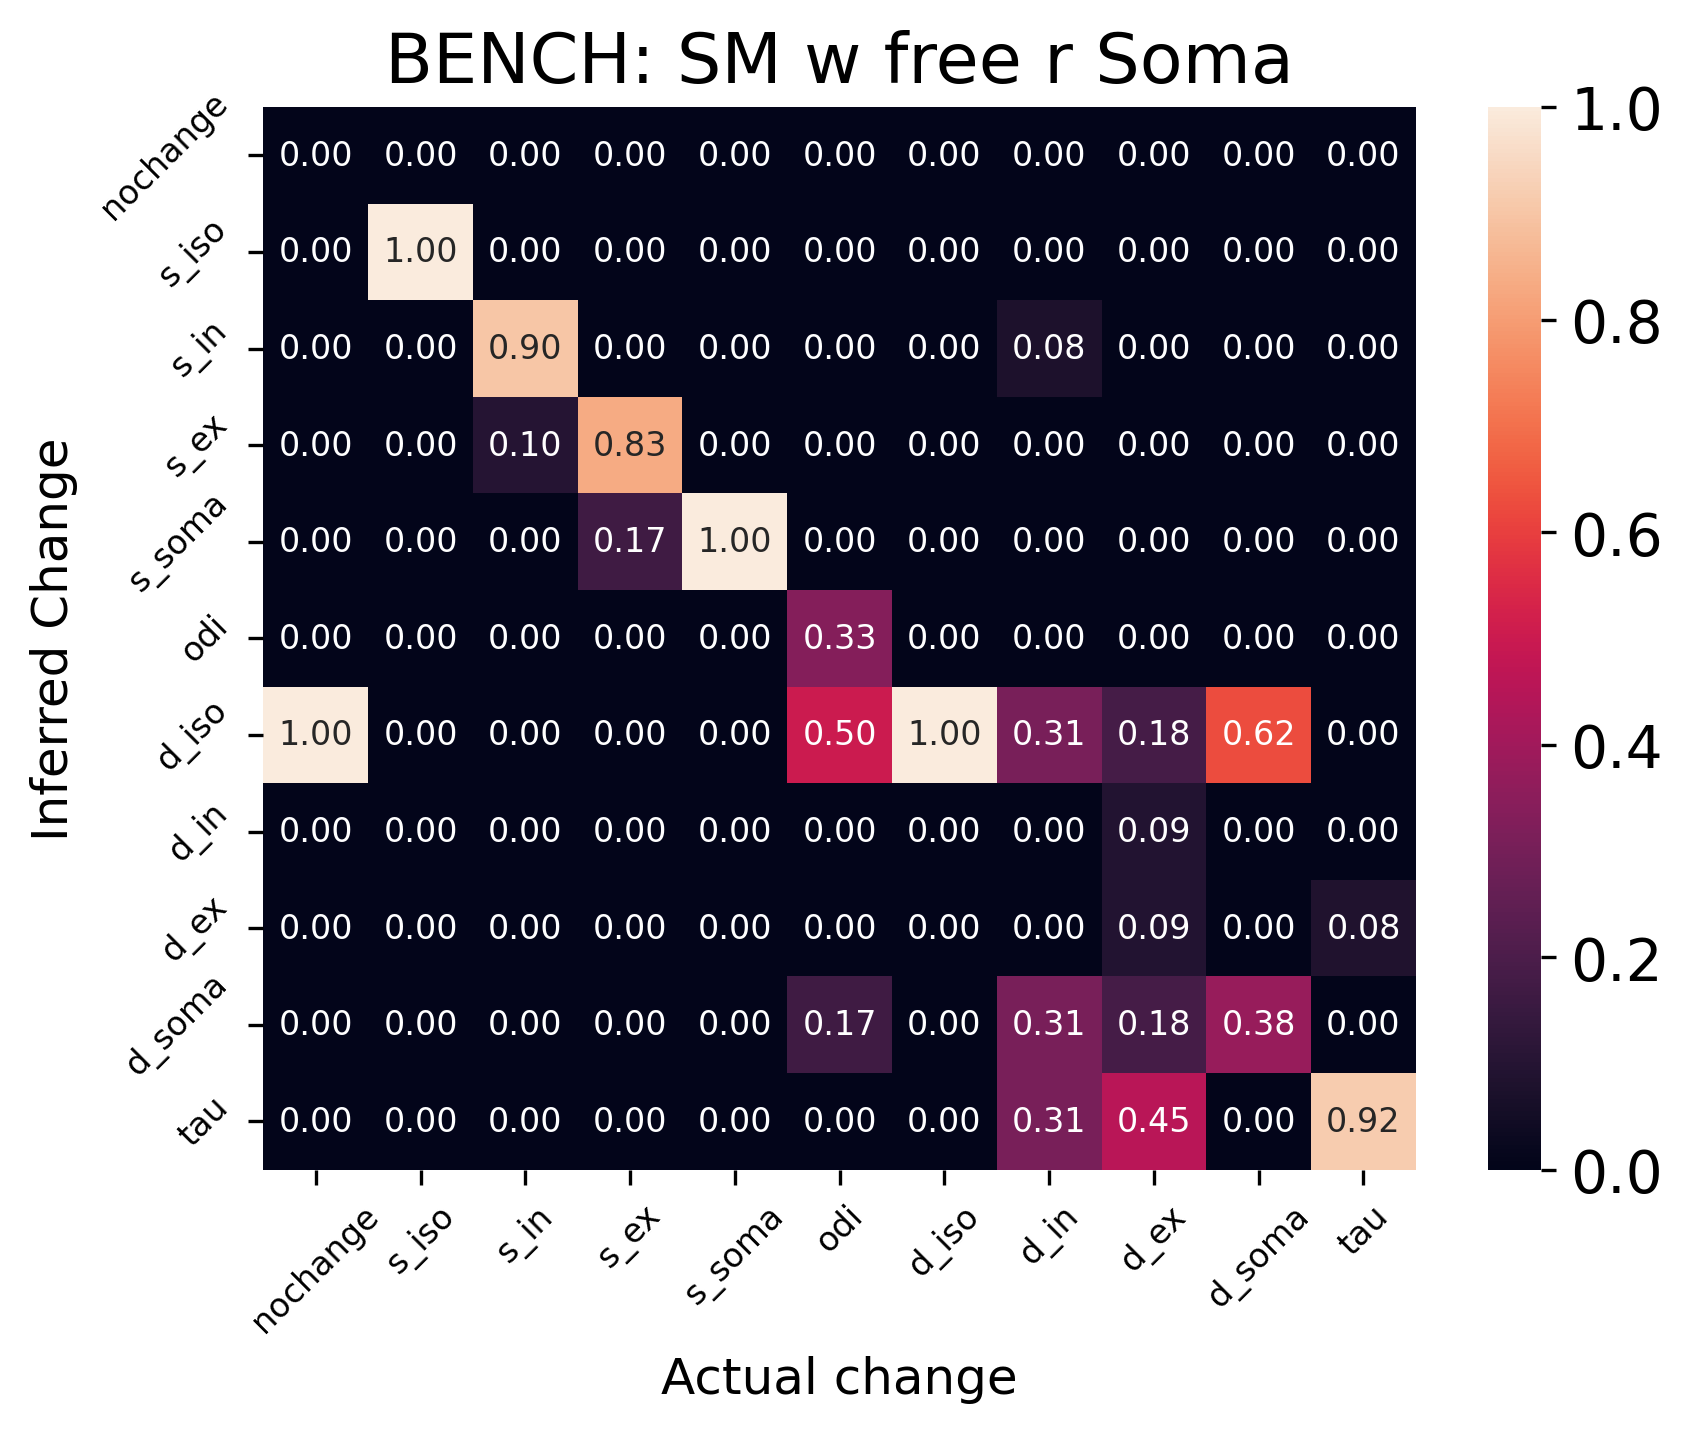

In [ ]:
conf_mat = confusion_matrix(true_change, infered_change_bench, normalize='true')
plot.plot_conf_mat(conf_mat, param_names=mdl.model_names, title='BENCH: SM w free r Soma')

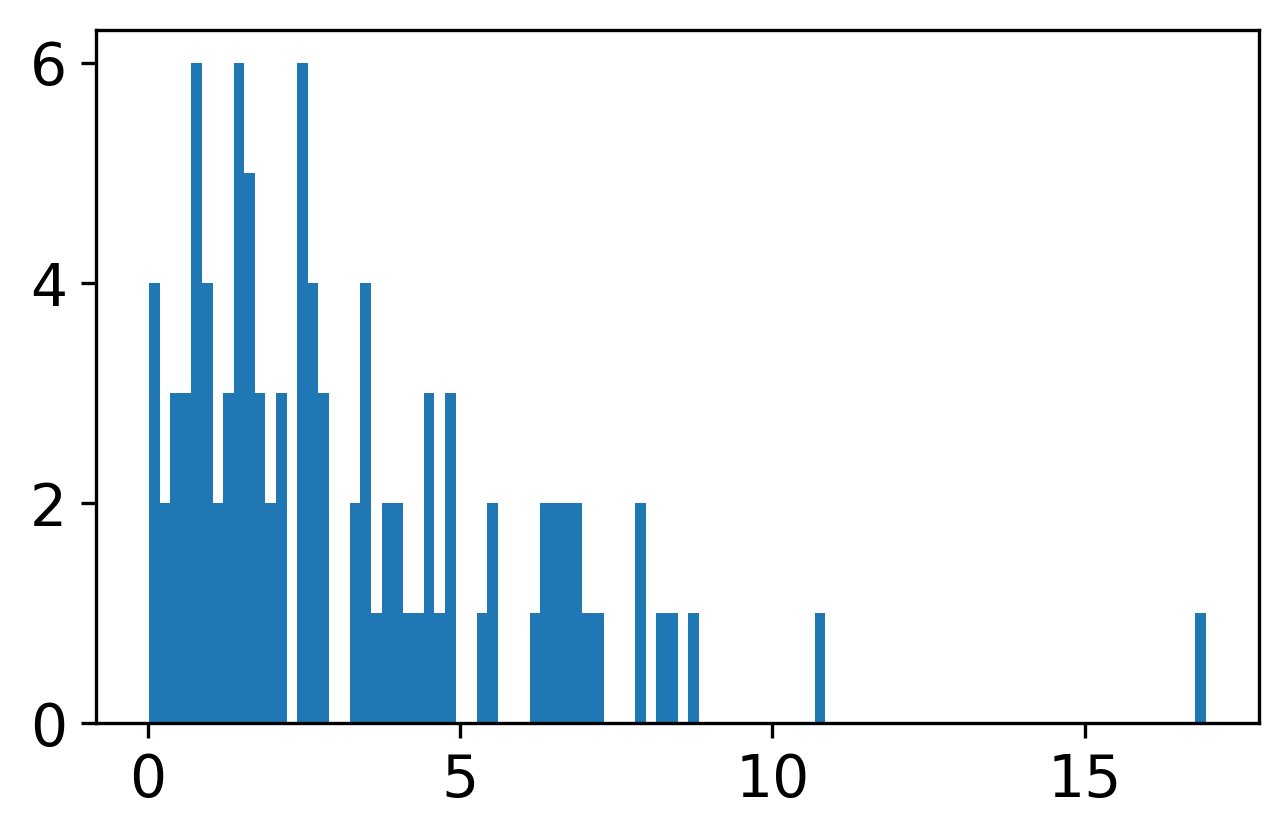

In [14]:
dv, offset, deviation = mdl.estimate_quality_of_fit(data, data2 - data, sn, infered_change_bench, amount)
plt.hist(deviation, 100);

In [15]:
def model_inv_tr(acq, noise_level, **p):
    return forward_model(bval=acq.bvals, bvec=acq.bvecs,**p) + noise_level * np.random.randn(acq.bvecs.shape[0])

def model_inv(**p):
    return forward_model(bval=acq.bvals, bvec=acq.bvecs,**p)

priors_inv = dict()
priors_inv['s_iso'] = st.truncnorm(loc=.5, scale=.2, a=-.5 / .2, b=np.inf)
priors_inv['s_in'] = st.truncnorm(loc=.5, scale=.2, a=-.5 / .2, b=np.inf)
priors_inv['s_ex'] = st.truncnorm(loc=.5, scale=.2, a=-.5 / .2, b=np.inf)
priors_inv['s_soma'] = st.truncnorm(loc=.05, scale=.03, a=-.05 / .03, b=np.inf)
priors_inv.update(priors_bench)
del priors_inv[('s_iso', 's_in', 's_ex', 's_soma')]

tr_inv = change_model.Trainer(forward_model=model_inv_tr, kwargs={'noise_level':0, 'acq':acq}, priors=priors_inv)

true_change_inv, sig1, sig2, sn = tr_inv.generate_test_samples(parallel=False, 
    n_samples=n_test_samples, noise_std=noise_level, n_repeats=2, effect_size=effect_size)
    
def tmp_func(j):
    pe1, std1 = model_inversion.map_fit(sig1[j], np.eye(len(sig1[j])), model_inv, priors_inv)
    pe2, std2 = model_inversion.map_fit(sig2[j], np.eye(len(sig2[j])), model_inv, priors_inv)
        
    return model_inversion.infer_change(np.atleast_2d(pe1), np.atleast_2d(std1), 
                                        np.atleast_2d(pe2), np.atleast_2d(std2), alpha=0.05)

res = Parallel(n_jobs=-1, verbose=True)(delayed(tmp_func)(j) for j in range(n_test_samples))
infered_change_inv = np.squeeze(np.array(res)[:, 0])

Generating 100 test samples:


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    6.7s
/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/Desktop/BENCH/BENCH_Adapted/bench-master/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:   21.0s finished


<Axes: title={'center': 'Parameter estimation: SM w Soma (in + soma)'}, xlabel='Actual change', ylabel='Inferred Change'>

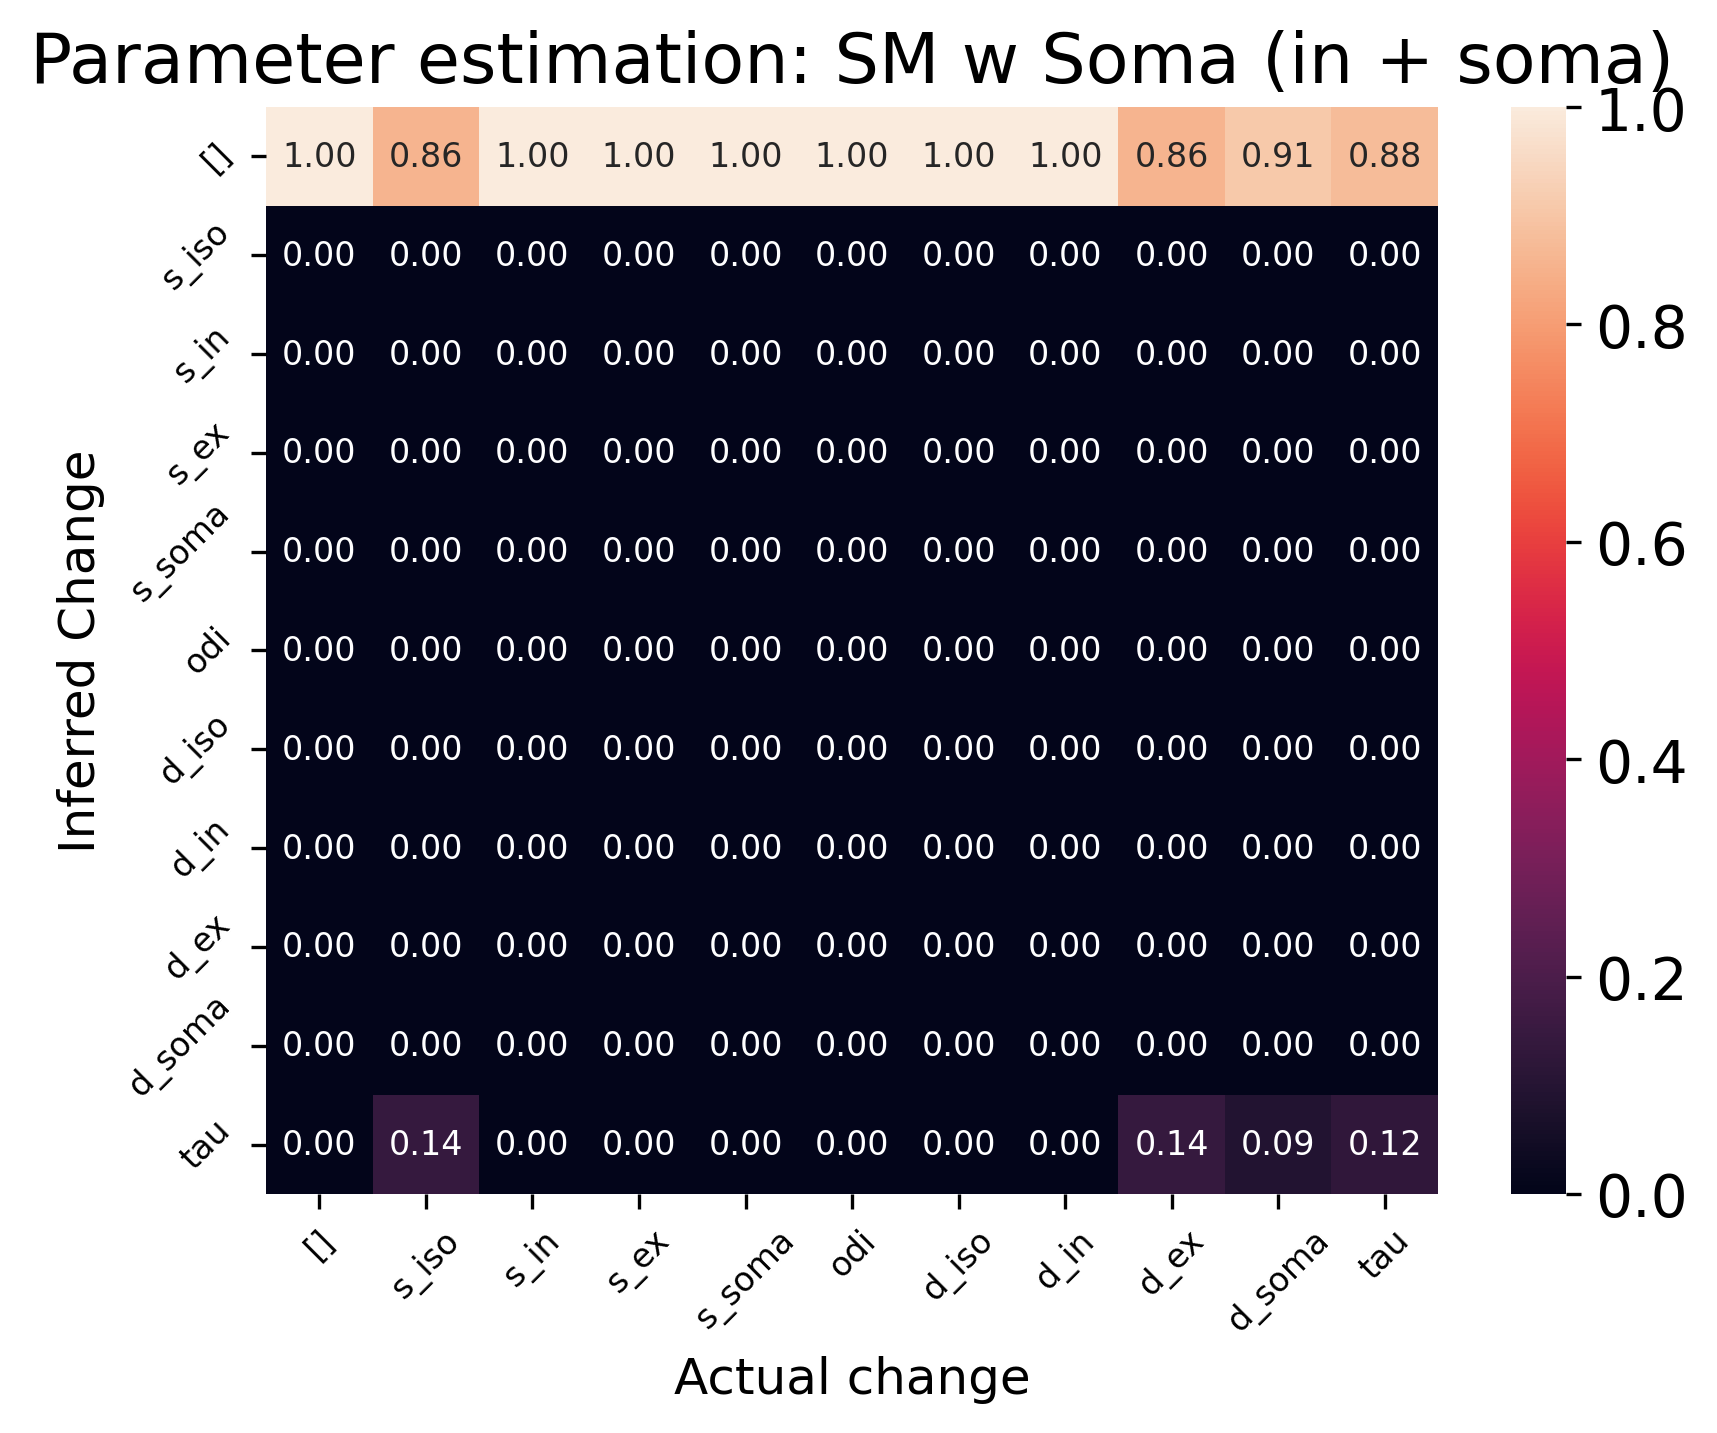

In [16]:
conf_mat_inv = confusion_matrix(true_change_inv, infered_change_inv, normalize='true')
plot.plot_conf_mat(conf_mat_inv, ['[]'] + list(priors_inv.keys()), title='Parameter estimation: SM w Soma (in + soma)')